<a href="https://colab.research.google.com/github/ryanaxiom/Applied-ML/blob/main/code/Day19_Carnegie.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Student Instructions**: Before you begin, click **File > Save a copy in Drive** so you do not lose your work!

In [1]:
url = ("https://raw.githubusercontent.com/ryanaxiom/Applied-ML/main/data/carnegie_data.csv")

import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.model_selection import cross_val_score
from sklearn.metrics import confusion_matrix, log_loss
from sklearn.metrics import roc_curve, roc_auc_score
carnegie_raw = pd.read_csv(url, encoding="cp1252")
carnegie = carnegie_raw.copy()
carnegie["research"] = carnegie["serd"] + carnegie["nonserd"]
d = carnegie[carnegie["research"].notna()].copy()
kf = KFold(n_splits=5, shuffle=True, random_state=309)
carnegie["med_yn"] = (carnegie["medical"] == 1).astype(int)
yn = carnegie["med_yn"]
cols = ["fallenr20", "grtenr20", "docrsdeg", "totdeg", "rooms"]
five = LogisticRegression(C=np.inf)     # C = 1/alpha: no penalty
prob = cross_val_predict(five, carnegie[cols], yn, cv=kf,
                         method="predict_proba")[:, 1]
print(carnegie.shape, int(yn.sum()), round(prob.sum(), 1))

(3939, 103) 199 197.1


0.5 0.0067 0.3065
0.3 0.0107 0.3769
0.2 0.016 0.4422
0.1 0.0329 0.5779
0.05 0.0829 0.7739


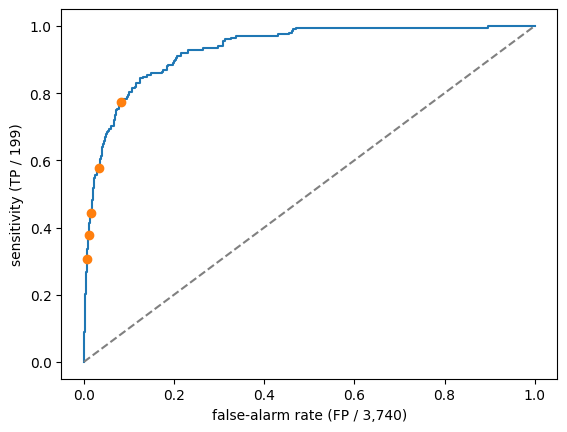

In [2]:
import matplotlib.pyplot as plt
fpr, tpr, thr = roc_curve(yn, prob)
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")   # a coin
for t in [0.5, 0.3, 0.2, 0.1, 0.05]:
    pred_t = (prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(yn, pred_t).ravel()
    plt.plot(fp / (fp + tn), tp / (tp + fn), "o", color="C1")
    print(t, round(fp / (fp + tn), 4), round(tp / (tp + fn), 4))
plt.xlabel("false-alarm rate (FP / 3,740)")
plt.ylabel("sensitivity (TP / 199)")
plt.show()

In [3]:
print(len(thr))
i = np.argmin(np.abs(fpr - 0.08))
print(round(fpr[i], 4), round(tpr[i], 4))

257
0.0805 0.7638


In [4]:
print(round(roc_auc_score(yn, prob), 4))
yes, no = prob[yn == 1], prob[yn == 0]
pairs = yes[:, None] > no[None, :]        # every (yes, no) pair
print(pairs.shape, round(pairs.mean(), 4))
folds = cross_val_score(five, carnegie[cols], yn, cv=kf,
                        scoring="roc_auc")
print(folds.round(4), round(folds.mean(), 4))

0.9319
(199, 3740) 0.9319
[0.9035 0.9372 0.9339 0.9482 0.9548] 0.9355


In [5]:
print(pairs.size, round(folds.mean() - roc_auc_score(yn, prob), 4))

744260 0.0036


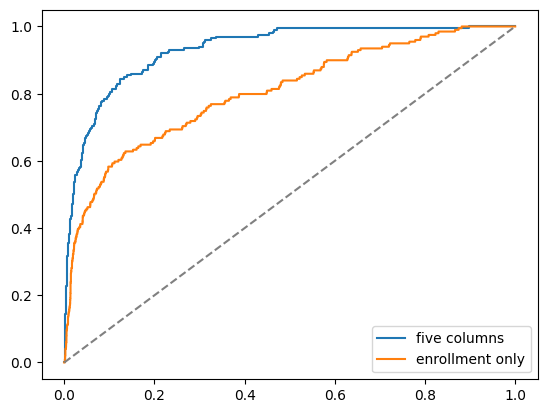

0.8113 0.8043


In [6]:
one = LogisticRegression(C=np.inf)
prob1 = cross_val_predict(one, carnegie[["fallenr20"]], yn, cv=kf,
                          method="predict_proba")[:, 1]
for name, p in [("five columns", prob), ("enrollment only", prob1)]:
    f, t, _ = roc_curve(yn, p)
    plt.plot(f, t, label=name)
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.legend()
plt.show()
folds1 = cross_val_score(one, carnegie[["fallenr20"]], yn, cv=kf,
                         scoring="roc_auc")
print(round(folds1.mean(), 4), round(roc_auc_score(yn, prob1), 4))

In [7]:
squared = prob**2                  # same order, smaller numbers
print(round(roc_auc_score(yn, prob), 4),
      round(roc_auc_score(yn, squared), 4))
print(round(log_loss(yn, prob), 4), round(log_loss(yn, squared), 4))
rate = np.full(len(yn), yn.mean())        # Day 2's naive model
print(round(roc_auc_score(yn, rate), 4),
      round(log_loss(yn, rate), 4))

0.9319 0.9319
0.1455 0.205
0.5 0.2


In [8]:
print(round(0.3**2, 2), round(0.8**2, 2))
naive = []
for train, test in kf.split(carnegie):
    rate_tr = yn.iloc[train].mean()
    naive.append(log_loss(yn.iloc[test], np.full(len(test), rate_tr)))
print(round(np.mean(naive), 4), round(log_loss(yn, rate), 4))

0.09 0.64
0.2001 0.2


0.5 61 25 0.709
0.3 75 40 0.652
0.2 88 60 0.595
0.1 115 123 0.483
0.05 154 310 0.332


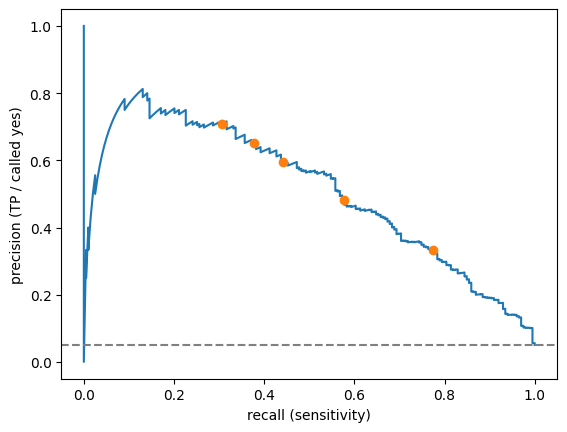

In [9]:
from sklearn.metrics import precision_recall_curve
prec, rec, _ = precision_recall_curve(yn, prob)
plt.plot(rec, prec)
plt.axhline(yn.mean(), linestyle="--", color="gray")  # base rate
for t in [0.5, 0.3, 0.2, 0.1, 0.05]:
    pred_t = (prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(yn, pred_t).ravel()
    plt.plot(tp / (tp + fn), tp / (tp + fp), "o", color="C1")
    print(t, tp, fp, round(tp / (tp + fp), 3))
plt.xlabel("recall (sensitivity)")
plt.ylabel("precision (TP / called yes)")
plt.show()

In [10]:
from sklearn.metrics import average_precision_score
pred_t = (prob >= 0.1).astype(int)
tn, fp, fn, tp = confusion_matrix(yn, pred_t).ravel()
print(round(tp / (tp + fn), 3), round(fp / (fp + tn), 3))
print(round(average_precision_score(yn, prob), 4), round(yn.mean(), 4))

0.578 0.033
0.5081 0.0505


In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
codes = pd.get_dummies(carnegie["basic2021"], prefix="basic")
X = pd.concat([carnegie[cols], codes.astype(int)], axis=1)
X_no25 = X.drop(columns="basic_25")       # the codebook's leak
pipe = make_pipeline(StandardScaler(), LogisticRegression())
for name, Xk in [("with code 25", X), ("without", X_no25)]:
    auc = cross_val_score(pipe, Xk, yn, cv=kf, scoring="roc_auc")
    ll = cross_val_score(pipe, Xk, yn, cv=kf,
                         scoring="neg_log_loss")
    print(name, Xk.shape[1], round(auc.mean(), 4),
          round(-ll.mean(), 4))

with code 25 38 0.9825 0.066
without 37 0.9822 0.069


In [12]:
ct = pd.crosstab(carnegie["basic2021"], yn)
ct["rate"] = (ct[1] / (ct[0] + ct[1])).round(3)
print(ct[ct[1] > 0])
base = cross_val_score(five, carnegie[cols], yn, cv=kf, scoring="roc_auc")
print(round(base.mean(), 4))

med_yn       0   1   rate
basic2021                
15          55  91  0.623
16         102  31  0.233
17         173  14  0.075
18         323   2  0.006
19         184   1  0.005
25           0  38  1.000
26         242   1  0.004
27           2  21  0.913
0.9355


In [13]:
plain = LogisticRegression(C=np.inf, max_iter=5000)
plain.fit(X, yn)                          # watch the warning
b = pd.Series(plain.coef_[0], index=X.columns)
print(plain.n_iter_[0], round(b["basic_25"], 2))
pipe.fit(X, yn)                           # default C=1, scaled
b1 = pd.Series(pipe[-1].coef_[0], index=X.columns)
print(round(b1["basic_25"], 3))
auc0 = cross_val_score(plain, X, yn, cv=kf, scoring="roc_auc")
print(round(auc0.mean(), 4))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


5000 11.98
1.204


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

0.9796


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [14]:
for ratio in [1, 5, 10, 20]:       # a miss costs ratio x an alarm
    best = None
    for t in np.arange(0.01, 1.00, 0.01):
        pred_t = (prob >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(yn, pred_t).ravel()
        cost = ratio * fn + fp
        if best is None or cost < best[1]:
            best = (round(float(t), 2), int(cost), int(fn), int(fp))
    print(ratio, best, round(1 / (1 + ratio), 3))

1 (0.42, 161, 132, 29) 0.5
5 (0.07, 505, 65, 180) 0.167
10 (0.05, 760, 45, 310) 0.091
20 (0.04, 1123, 34, 443) 0.048


In [15]:
bins = pd.cut(prob, [0, 0.05, 0.1, 0.2, 0.5, 1])
table = pd.DataFrame({"bin": bins, "p": prob, "yes": yn.values})
print(table.groupby("bin", observed=True)
           .agg(n=("yes", "size"), mean_p=("p", "mean"),
                rate=("yes", "mean")).round(3))

                n  mean_p   rate
bin                             
(0.0, 0.05]  3475   0.023  0.013
(0.05, 0.1]   226   0.067  0.173
(0.1, 0.2]     90   0.140  0.300
(0.2, 0.5]     62   0.312  0.435
(0.5, 1.0]     86   0.824  0.709
